In [1]:
# =====================================================================
# Cell 1 — Install
# =====================================================================
!pip install -q torch torchvision timm huggingface_hub tqdm numpy pyyaml pandas matplotlib


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip


In [2]:
# =====================================================================
# Cell 2 — Config
# =====================================================================
import os, json, time, zipfile, shutil, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets
from timm.data import Mixup, create_transform
from timm.loss import SoftTargetCrossEntropy
from timm.scheduler import CosineLRScheduler
from timm.models.layers import DropPath, trunc_normal_
from huggingface_hub import hf_hub_download, login, whoami
from tqdm.auto import tqdm

DATA_ROOT    = "./data"
RAW_ROOT     = "./data/imagenet100_raw"
HF_REPO      = "asafaa/imagent100"
OUTPUT_DIR   = "./outputs/phase0"
EPOCHS       = 100
BATCH_SIZE   = 128
LR           = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS= 10
GRAD_CLIP    = 1.0
NUM_WORKERS  = 8
NUM_CLASSES  = 100
SEED         = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA H200


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [ ]:
# =====================================================================
# Cell 3 — HuggingFace login
# =====================================================================
login(token="hf_key")
print(f"✓ {whoami()['name']}")

✓ Ranjan637


In [4]:
# =====================================================================
# Cell 4 — Download zips
# =====================================================================
def download_all_chunks(repo_id, raw_root, train_parts=5, val_parts=5):
    os.makedirs(raw_root, exist_ok=True)
    for split, n in [("train", train_parts), ("val", val_parts)]:
        for p in range(1, n + 1):
            fn = f"imagenet100_{split}_part{p}.zip"
            print(f"↓ {fn}")
            hf_hub_download(repo_id=repo_id, filename=fn,
                            repo_type="dataset", local_dir=raw_root)
    hf_hub_download(repo_id=repo_id, filename="Labels.json",
                    repo_type="dataset", local_dir=raw_root)
    print("Done.")

download_all_chunks(HF_REPO, RAW_ROOT)

↓ imagenet100_train_part1.zip
↓ imagenet100_train_part2.zip
↓ imagenet100_train_part3.zip
↓ imagenet100_train_part4.zip
↓ imagenet100_train_part5.zip
↓ imagenet100_val_part1.zip
↓ imagenet100_val_part2.zip
↓ imagenet100_val_part3.zip
↓ imagenet100_val_part4.zip
↓ imagenet100_val_part5.zip
Done.


In [5]:
# =====================================================================
# Cell 5 — Extract + merge
# =====================================================================
def extract_and_merge(raw_root, data_root, train_parts=5, val_parts=5):
    tmp = os.path.join(raw_root, "_extract_tmp")
    os.makedirs(tmp, exist_ok=True)
    for split, n in [("train", train_parts), ("val", val_parts)]:
        split_dir = os.path.join(data_root, split)
        os.makedirs(split_dir, exist_ok=True)
        for p in range(1, n + 1):
            zp = os.path.join(raw_root, f"imagenet100_{split}_part{p}.zip")
            if not os.path.exists(zp): continue
            et = os.path.join(tmp, f"{split}_{p}")
            os.makedirs(et, exist_ok=True)
            with zipfile.ZipFile(zp) as zf:
                zf.extractall(et)
            for root, _, files in os.walk(et):
                if any(f.lower().endswith((".jpg",".jpeg",".png")) for f in files):
                    cls = os.path.basename(root)
                    dest = os.path.join(split_dir, cls)
                    os.makedirs(dest, exist_ok=True)
                    for f in files:
                        if f.lower().endswith((".jpg",".jpeg",".png")):
                            d = os.path.join(dest, f)
                            if not os.path.exists(d):
                                shutil.move(os.path.join(root, f), d)
    shutil.rmtree(tmp, ignore_errors=True)
    print("Done.")

extract_and_merge(RAW_ROOT, DATA_ROOT)

Done.


In [6]:
# =====================================================================
# Cell 6 — Verify
# =====================================================================
for split in ["train","val"]:
    d = os.path.join(DATA_ROOT, split)
    cls = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d,c))]
    n = sum(len(f) for _,_,f in os.walk(d))
    print(f"{split}: {len(cls)} classes, {n} images")

train: 100 classes, 128982 images
val: 100 classes, 5000 images


In [15]:
#cell - 7

class MRConv2d(nn.Module):
    """Max-relative graph conv: correct direction, max aggregation, FP32.

    Handles the degenerate case N=1 (k=0): no neighbors to aggregate,
    so fall back to a plain linear projection of the center features.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.fc = nn.Linear(in_ch * 2, out_ch)

    @torch.amp.autocast('cuda', enabled=False)
    def forward(self, x, edge_index, k):
        x = x.float()

        # ---- Degenerate case: no graph structure (N=1 at final stage) ----
        if k == 0 or edge_index.numel() == 0:
            x_zero = torch.zeros_like(x)
            return self.fc(torch.cat([x, x_zero], dim=-1))

        row, col = edge_index                  # row=center, col=neighbor
        x_rel = x[col] - x[row]                # neighbor - center
        BN = x.size(0)
        x_rel = x_rel.view(BN, k, -1)          # (BN, k, C)
        x_max = x_rel.max(dim=1)[0]            # max over k neighbors
        return self.fc(torch.cat([x, x_max], dim=-1))

In [17]:
#cell 7 phase 2

def _knn(self, x):
    B, C, H, W = x.shape
    N = H * W
    ke = min(self.k, N - 1)

    # ---- Degenerate case: single token, no neighbors ----
    if ke == 0:
        ei = torch.empty((2, 0), dtype=torch.long, device=x.device)
        return ei, B, N, 0

    with torch.amp.autocast('cuda', enabled=False):
        xf = x.permute(0, 2, 3, 1).reshape(B, N, C).float()
        xn = F.normalize(xf, dim=-1, eps=1e-6)
        sim = torch.bmm(xn, xn.transpose(1, 2))
        sim.diagonal(dim1=1, dim2=2).fill_(-float('inf'))
        _, idx = sim.topk(ke, dim=-1)

    base = torch.arange(B, device=x.device).view(B, 1, 1) * N
    row = (torch.arange(N, device=x.device).view(1, N, 1) + base).expand(B, N, ke)
    col = idx + base.expand(B, N, ke)
    ei = torch.stack([row.reshape(-1), col.reshape(-1)], 0)
    return ei, B, N, ke

In [18]:
# =====================================================================
# Cell 8 — Data loaders
# =====================================================================
def build_loaders(root, bs=128, nw=8):
    tr_t = create_transform(224, True, color_jitter=0.4,
        auto_augment='rand-m9-mstd0.5-inc1', interpolation='bicubic',
        re_prob=0.25, re_mode='pixel', re_count=1)
    vl_t = create_transform(224, False, interpolation='bicubic', crop_pct=0.95)
    tr = datasets.ImageFolder(os.path.join(root,"train"), tr_t)
    vl = datasets.ImageFolder(os.path.join(root,"val"),   vl_t)
    tr_l = DataLoader(tr, bs, True, num_workers=nw, pin_memory=True,
                      drop_last=True, persistent_workers=nw>0)
    vl_l = DataLoader(vl, bs, False, num_workers=nw, pin_memory=True,
                      persistent_workers=nw>0)
    return tr_l, vl_l, len(tr.classes)

train_loader, val_loader, n_classes = build_loaders(DATA_ROOT, BATCH_SIZE, NUM_WORKERS)
print(f"Train: {len(train_loader)} batches | Val: {len(val_loader)} batches")

Train: 1007 batches | Val: 40 batches


In [19]:
# =====================================================================
# Cell 9 — OVERFIT TEST (must pass before full training)
# =====================================================================
# If the model cannot memorize 5 batches in 30 epochs, the architecture
# is still broken. Do NOT run Cell 10 until this prints ≥ 0.95.

print("="*70); print("OVERFIT TEST: 5 batches"); print("="*70)

diag = pyramid_vig_ti(NUM_CLASSES).to(DEVICE)
opt  = optim.AdamW(diag.parameters(), lr=2e-3, weight_decay=0.0)
lf   = nn.CrossEntropyLoss()
sc   = GradScaler('cuda')

batches = [b for i, b in enumerate(train_loader) if i < 5]
n_samp = sum(b[0].size(0) for b in batches)
print(f"5 batches = {n_samp} samples")

for ep in range(30):
    diag.train()
    for imgs, tgts in batches:
        imgs, tgts = imgs.to(DEVICE), tgts.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        with autocast('cuda'):
            loss = lf(diag(imgs), tgts)
        sc.scale(loss).backward()
        sc.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(diag.parameters(), 1.0)
        sc.step(opt); sc.update()
    if (ep+1) % 5 == 0:
        diag.eval()
        c = t = 0
        with torch.no_grad(), autocast('cuda'):
            for imgs, tgts in batches:
                imgs, tgts = imgs.to(DEVICE), tgts.to(DEVICE)
                c += (diag(imgs).argmax(1) == tgts).sum().item()
                t += tgts.size(0)
        print(f"Epoch {ep+1:2d}: overfit acc = {c/t:.4f}")

del diag, opt, sc; torch.cuda.empty_cache()
print("\n→ If acc >= 0.95, proceed to Cell 10. If not, STOP.")

OVERFIT TEST: 5 batches
5 batches = 640 samples
Epoch  5: overfit acc = 0.0359
Epoch 10: overfit acc = 0.0625
Epoch 15: overfit acc = 0.1344
Epoch 20: overfit acc = 0.2578
Epoch 25: overfit acc = 0.3656
Epoch 30: overfit acc = 0.6281

→ If acc >= 0.95, proceed to Cell 10. If not, STOP.


In [20]:
# =====================================================================
# Cell 10 — Full training (NaN detection + grad monitoring)
# =====================================================================
def train_epoch(model, loader, opt, sc, crit, mixup, device):
    model.train(); tl = 0.0; n = 0; gns = []
    for imgs, tgts in tqdm(loader, desc="Train", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        tgts = tgts.to(device, non_blocking=True)
        if mixup is not None:
            imgs, tgts = mixup(imgs, tgts)
        opt.zero_grad(set_to_none=True)
        with autocast('cuda'):
            loss = crit(model(imgs), tgts)
        if torch.isnan(loss) or torch.isinf(loss):
            print("  ⚠ NaN/Inf — skipping batch")
            opt.zero_grad(set_to_none=True); continue
        sc.scale(loss).backward()
        sc.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        gns.append(float(gn))
        sc.step(opt); sc.update()
        tl += loss.item() * imgs.size(0); n += imgs.size(0)
    return tl / max(n,1), (np.mean(gns) if gns else 0.0), (max(gns) if gns else 0.0)


@torch.no_grad()
def validate(model, loader, crit, device):
    model.eval(); tl = c = n = 0
    for imgs, tgts in tqdm(loader, desc="Val", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        tgts = tgts.to(device, non_blocking=True)
        with autocast('cuda'):
            out = model(imgs)
            tl += crit(out, tgts).item() * imgs.size(0)
        c += (out.argmax(1) == tgts).sum().item(); n += tgts.size(0)
    return tl / n, c / n


def run_experiment_0_1():
    print("="*80); print("EXPERIMENT 0.1: ViG-Ti on ImageNet-100"); print("="*80)
    model = pyramid_vig_ti(NUM_CLASSES).to(DEVICE)
    print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.2f}M")

    # Option A: always mix, but weak alphas (safe w.r.t. SoftTargetCrossEntropy)
    mixup = Mixup(mixup_alpha=0.2, cutmix_alpha=0.2, cutmix_minmax=None,
                  prob=1.0, switch_prob=0.5, mode='batch',
                  label_smoothing=0.1, num_classes=NUM_CLASSES)
    tr_c = SoftTargetCrossEntropy()
    vl_c = nn.CrossEntropyLoss()

    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if p.ndim <= 1 or 'norm' in n.lower() or 'bias' in n.lower():
            no_decay.append(p)
        else:
            decay.append(p)
    opt = optim.AdamW([{'params': decay,    'weight_decay': WEIGHT_DECAY},
                       {'params': no_decay, 'weight_decay': 0.0}], lr=LR)
    sc  = GradScaler('cuda')
    sch = CosineLRScheduler(opt, t_initial=EPOCHS, lr_min=1e-6,
                            warmup_t=WARMUP_EPOCHS, warmup_lr_init=1e-6)
    sch.step(0)

    best, hist, nan_streak = 0.0, [], 0
    for ep in range(EPOCHS):
        t0 = time.time()
        tl, avg_gn, max_gn = train_epoch(model, train_loader, opt, sc, tr_c, mixup, DEVICE)
        vl, va = validate(model, val_loader, vl_c, DEVICE)
        sch.step(ep + 1)
        dt = time.time() - t0
        hist.append(dict(epoch=ep+1, train_loss=tl, val_loss=vl, val_acc=va,
                         lr=opt.param_groups[0]['lr'], time=dt,
                         avg_grad_norm=avg_gn, max_grad_norm=max_gn))
        flag = ""
        if va > best:
            best = va
            torch.save(model.state_dict(),
                       os.path.join(OUTPUT_DIR, "best_vig_ti.pth"))
            flag = " ★"
        print(f"Epoch {ep+1:3d}/{EPOCHS} | TrL {tl:.4f} | VaL {vl:.4f} | "
              f"Acc {va:.4f} | GN {avg_gn:.2f}/{max_gn:.2f} | "
              f"LR {opt.param_groups[0]['lr']:.2e} | {dt:.1f}s{flag}")
        nan_streak = nan_streak + 1 if math.isnan(tl) else 0
        if nan_streak >= 3:
            print("❌ 3 consecutive NaN epochs — aborting.")
            break
    print(f"\nBest val acc: {best:.4f}")
    pd.DataFrame(hist).to_csv(os.path.join(OUTPUT_DIR, "history.csv"), index=False)
    return best, hist

In [21]:
# =====================================================================
# Cell 11 — Run full training
# =====================================================================
best_acc, history = run_experiment_0_1()

EXPERIMENT 0.1: ViG-Ti on ImageNet-100
Params: 5.87M


Epoch   1/100 | TrL 4.6410 | VaL 4.5879 | Acc 0.0192 | GN 3.06/3.74 | LR 1.01e-04 | 70.5s ★


Epoch   2/100 | TrL 4.4801 | VaL 4.0612 | Acc 0.0912 | GN 2.55/5.31 | LR 2.01e-04 | 70.1s ★


Epoch   3/100 | TrL 4.3847 | VaL 3.8780 | Acc 0.1186 | GN 2.83/5.86 | LR 3.01e-04 | 71.3s ★


Epoch   4/100 | TrL 4.3196 | VaL 3.7868 | Acc 0.1406 | GN inf/inf | LR 4.01e-04 | 70.8s ★


Epoch   5/100 | TrL 4.2718 | VaL 3.6988 | Acc 0.1484 | GN 2.67/6.47 | LR 5.01e-04 | 71.1s ★


... (91 outputs left out)

Epoch  97/100 | TrL 3.1813 | VaL 1.7678 | Acc 0.5648 | GN inf/inf | LR 3.22e-06 | 77.1s


Epoch  98/100 | TrL 3.1775 | VaL 1.7677 | Acc 0.5644 | GN 3.56/5.13 | LR 1.99e-06 | 75.2s


Epoch  99/100 | TrL 3.1728 | VaL 1.7679 | Acc 0.5694 | GN inf/inf | LR 1.25e-06 | 74.4s ★


Epoch 100/100 | TrL 3.1459 | VaL 1.7639 | Acc 0.5666 | GN 3.56/5.21 | LR 1.00e-06 | 74.5s

Best val acc: 0.5694


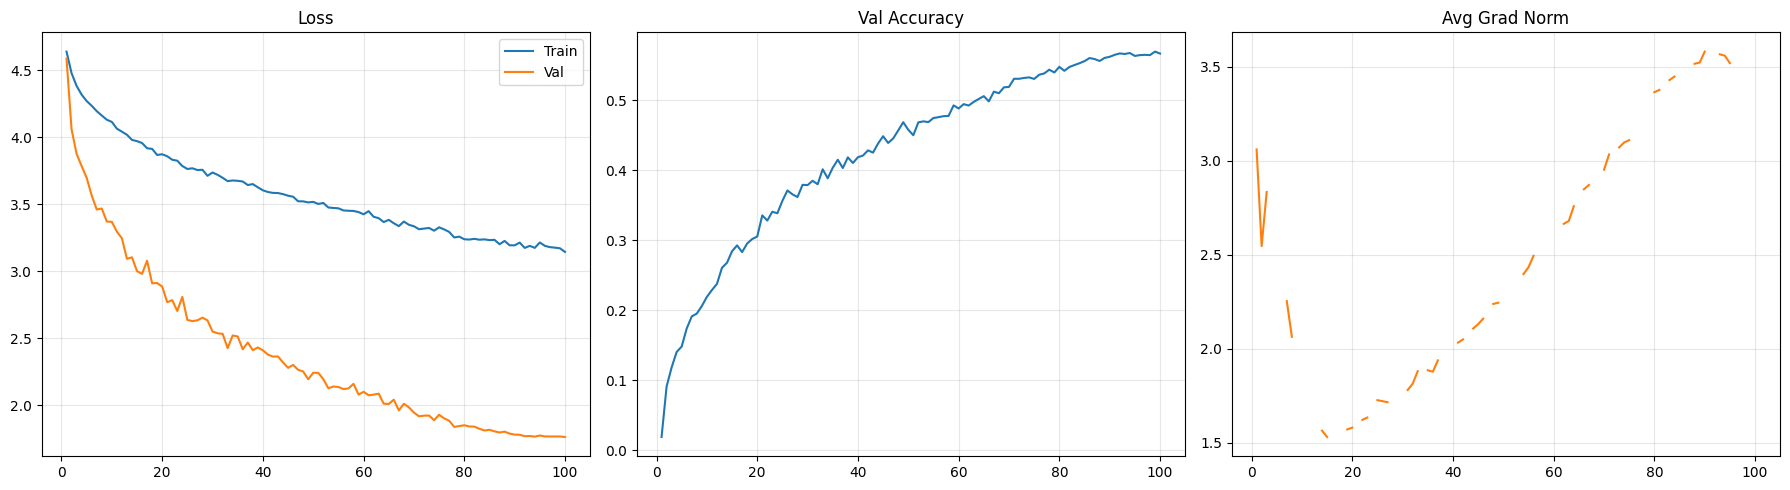

In [22]:
# =====================================================================
# Cell 12 — Curves
# =====================================================================
df = pd.read_csv(os.path.join(OUTPUT_DIR, "history.csv"))
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].plot(df.epoch, df.train_loss, label="Train"); ax[0].plot(df.epoch, df.val_loss, label="Val")
ax[0].set_title("Loss"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(df.epoch, df.val_acc, color="tab:blue")
ax[1].set_title("Val Accuracy"); ax[1].grid(alpha=0.3)
ax[2].plot(df.epoch, df.avg_grad_norm, color="tab:orange")
ax[2].set_title("Avg Grad Norm"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()